# Praktikum 3 - Regresi dengan Keras

**Nama:** Radit Firansah  
**NIM:** 244107020196

Memprediksi harga rumah menggunakan JST regresi: data dummy dan dataset Boston Housing.

## Bagian A - Regresi Data Dummy (Harga Rumah)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi
print("Prediksi:", model.predict(X_test))

I0000 00:00:1790790301.747748   48205 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790790301.748171   48205 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790790301.782480   48205 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790790302.748819   48205 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790790302.749088   48205 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


E0000 00:00:1790790303.254647   48205 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1790790303.254875   48337 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1790790303.270548   48205 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


Prediksi: [[-0.0161034]]


## Tugas 4 - Pengaruh Learning Rate

Membandingkan loss akhir untuk beberapa nilai learning rate pada model regresi dummy.

In [2]:
def latih_regresi(lr):
    tf.keras.utils.set_random_seed(42)
    m = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = m.fit(X_train, y_train, epochs=100, verbose=0)
    return h.history['loss'][-1]

print(f"{'Learning Rate':<16}{'Loss Akhir':<12}")
for lr in [0.0001, 0.001, 0.01, 0.1]:
    loss = latih_regresi(lr)
    print(f"{lr:<16}{loss:<12.6f}")

Learning Rate   Loss Akhir  


0.0001          0.988751    


0.001           0.600234    


0.01            0.001676    


0.1             0.000010    


### Kesimpulan Tugas 4

- Learning rate terlalu kecil membuat proses belajar lambat sehingga loss akhir masih tinggi.
- Learning rate terlalu besar dapat membuat training tidak stabil atau gagal konvergen.
- Nilai menengah (sekitar `0.001`-`0.01`) biasanya memberi hasil terbaik.

## Bagian B - Regresi Dataset Boston Housing

> **Catatan:** fungsi `load_boston` sudah **dihapus** dari scikit-learn (sejak versi 1.2)
> karena alasan etis. Sebagai gantinya kita memakai `fetch_openml('boston', version=1)`
> yang mengambil dataset yang sama dari OpenML.

In [3]:
# MLP regresi (Keras)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# 1. Load (load_boston sudah dihapus, pakai fetch_openml)
data = fetch_openml('boston', version=1, as_frame=False, parser='auto')
X = data.data; y = data.target

# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

# 3. Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

## Plot Loss & MAE

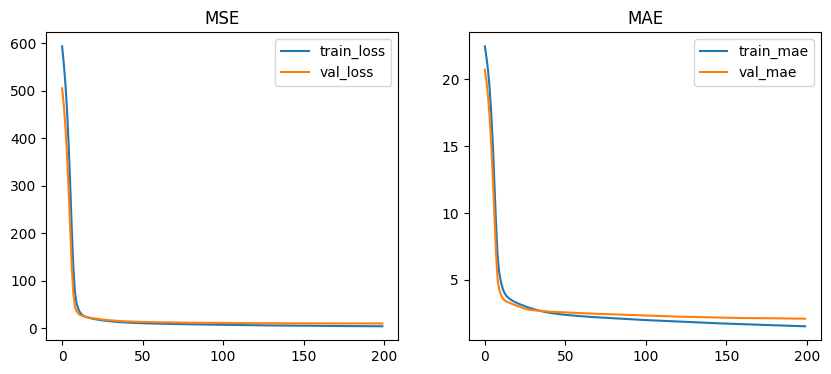

In [4]:
# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

## Evaluasi RMSE

In [5]:
from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


RMSE: 3.1833410631709365


### Kesimpulan Bagian B

- Model MLP (64-32-1) mampu menurunkan MSE dan MAE secara konsisten pada data train maupun validasi.
- RMSE yang dihasilkan menunjukkan rata-rata kesalahan prediksi harga rumah dalam ribuan dolar.